# Исследование заведений общественного питания в Москве
- Автор: Шалак Лидия
- Дата: 20 сентября 2026 г

### Цели и задачи проекта
В этой тетрадке используем датасеты `https://code.s3.yandex.net/datasets/rest_info_df.csv` и `https://code.s3.yandex.net//datasets/rest_price.csv`, которые содержат информацию о заведениях общественного питания и информацию о среднем чеке в заведениях общественного питания. Проведём предобработку данных: определим пропущенные и ошибочные значения, правильные названия столбцов и типов данных, найдём дубликаты.

### Описание данных

`rest_info_df.csv`

- `name` — название заведения;
- `address` — адрес заведения;
- `district` — административный район, в котором находится заведение, например Центральный административный округ;
- `category` — категория заведения, например «кафе», «пиццерия» или «кофейня»;
- `hours` — информация о днях и часах работы;
- `rating` — рейтинг заведения по оценкам пользователей в Яндекс Картах (высшая оценка — 5.0);
- `chain` — число, выраженное 0 или 1, которое показывает, является ли заведение сетевым (для маленьких сетей могут встречаться ошибки):
0 — заведение не является сетевым;
1 — заведение является сетевым.
- `seats` — количество посадочных мест

`rest_price.csv`

- `price` — категория цен в заведении, например «средние», «ниже среднего», «выше среднего» и так далее;
- `avg_bill` — хранит среднюю стоимость заказа в виде диапазона, например:
«Средний счёт: 1000–1500 ₽»;
«Цена чашки капучино: 130–220 ₽»;
«Цена бокала пива: 400–600 ₽».
и так далее;
- `middle_avg_bill` — число с оценкой среднего чека, которое указано только для значений из столбца avg_bill, начинающихся с подстроки «Средний счёт»:
Если в строке указан ценовой диапазон из двух значений, в столбец войдёт медиана этих двух значений.
Если в строке указано одно число — цена без диапазона, то в столбец войдёт это число.
Если значения нет или оно не начинается с подстроки «Средний счёт», то в столбец ничего не войдёт.
- `middle_coffee_cup` — число с оценкой одной чашки капучино, которое указано только для значений из столбца avg_bill, начинающихся с подстроки «Цена одной чашки капучино»:
Если в строке указан ценовой диапазон из двух значений, в столбец войдёт медиана этих двух значений.
Если в строке указано одно число — цена без диапазона, то в столбец войдёт это число.
Если значения нет или оно не начинается с подстроки «Цена одной чашки капучино», то в столбец ничего не войдёт.

In [1]:
# Импортируем библиотеку pandas
import pandas as pd
# Импортируем библиотеку matplotlib для построения графиков
import matplotlib.pyplot as plt

In [2]:
# Выгружаем данные в переменные rest_info_df и rest_price_df
rest_info_df = pd.read_csv('https://code.s3.yandex.net/datasets/rest_info.csv')
rest_price_df = pd.read_csv('https://code.s3.yandex.net//datasets/rest_price.csv') 

In [3]:
# Выводим первые строки датафрейма на экран
rest_info_df.head()

,id,name,category,address,district,hours,rating,chain,seats
0,0c3e3439a8c64ea5bf6ecd6ca6ae19f0,WoWфли,кафе,"Москва, улица Дыбенко, 7/1",Северный административный округ,"ежедневно, 10:00–22:00",5.0,0,NaN
1,045780ada3474c57a2112e505d74b633,Четыре комнаты,ресторан,"Москва, улица Дыбенко, 36, корп. 1",Северный административный округ,"ежедневно, 10:00–22:00",4.5,0,4.0
2,1070b6b59144425896c65889347fcff6,Хазри,кафе,"Москва, Клязьминская улица, 15",Северный административный округ,"пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00...",4.6,0,45.0
3,03ac7cd772104f65b58b349dc59f03ee,Dormouse Coffee Shop,кофейня,"Москва, улица Маршала Федоренко, 12",Северный административный округ,"ежедневно, 09:00–22:00",5.0,0,NaN
4,a163aada139c4c7f87b0b1c0b466a50f,Иль Марко,пиццерия,"Москва, Правобережная улица, 1Б",Северный административный округ,"ежедневно, 10:00–22:00",5.0,1,148.0


In [4]:
# Выводим информацию о датафрейме
rest_info_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8406 entries, 0 to 8405
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        8406 non-null   object 
 1   name      8406 non-null   object 
 2   category  8406 non-null   object 
 3   address   8406 non-null   object 
 4   district  8406 non-null   object 
 5   hours     7870 non-null   object 
 6   rating    8406 non-null   float64
 7   chain     8406 non-null   int64  
 8   seats     4795 non-null   float64
dtypes: float64(2), int64(1), object(6)
memory usage: 591.2+ KB


Датасет `rest_info.csv` содержит 9 столбцов и 8406 строк, в которых представлена информация о заведениях общественного питания Москвы.

Изучим типы данных и их корректность:

**Числовые значения с плавающей запятой (float64)** 2 столбца: `rating` – рейтинг заведения и `seats` – количество посадочных мест.

**Целочисленные значения (int64)**  1 столбец `chain`– бинарный тип значения 0 и 1, его можно оптимизировать до `int8`.

**Строковые значения (object)** 6 столбцов: `id`, `name`, `category`, `address`, `district`.

Пропуски в данных содержаться в столбцах `hours` и `seats`.

In [5]:
# Выводим первые строки датафрейма на экран
rest_price_df.head()

,id,price,avg_bill,middle_avg_bill,middle_coffee_cup
0,045780ada3474c57a2112e505d74b633,выше среднего,Средний счёт:1500–1600 ₽,1550.0,NaN
1,1070b6b59144425896c65889347fcff6,средние,Средний счёт:от 1000 ₽,1000.0,NaN
2,03ac7cd772104f65b58b349dc59f03ee,NaN,Цена чашки капучино:155–185 ₽,NaN,170.0
3,a163aada139c4c7f87b0b1c0b466a50f,средние,Средний счёт:400–600 ₽,500.0,NaN
4,8a343546b24e4a499ad96eb7d0797a8a,средние,NaN,NaN,NaN


In [6]:
# Выводим информацию о датафрейме
rest_price_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4058 entries, 0 to 4057
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 4058 non-null   object 
 1   price              3315 non-null   object 
 2   avg_bill           3816 non-null   object 
 3   middle_avg_bill    3149 non-null   float64
 4   middle_coffee_cup  535 non-null    float64
dtypes: float64(2), object(3)
memory usage: 158.6+ KB


Датасет `rest_price.csv` содержит 5 столбцов и 4058 строк, в которых представлена информация о среднем чеке в заведениях общественного питания.

Изучим типы данных и их корректность:

**Числовые значения с плавающей запятой (float64)** 2 столбца: `middle_avg_bill` – число с оценкой среднего чека и `middle_coffee_cup` – число с оценкой одной чашки капучино.

**Строковые значения (object)** 3 столбца: `id`, `price`, `avg_bill`. `price` – категория цен в заведении имеет ограниченный набор значений, можно привести к типу `category` для оптимизации хранения.

Пропуски в данных содержаться во всех столбцах, кроме `id`. 

Значения столбца `middle_avg_bill` зависят от значений из столбца `avg_bill`, начинающихся с подстроки «Средний счёт»:
Если в строке указан ценовой диапазон из двух значений, в столбец войдёт медиана этих двух значений.
Если в строке указано одно число — цена без диапазона, то в столбец войдёт это число.
Если значения нет или оно не начинается с подстроки «Средний счёт», то в столбец ничего не войдёт.

Значения столбца `middle_coffee_cup` зависят от значений из столбца `avg_bill`, начинающихся с подстроки «Цена одной чашки капучино»:
Если в строке указан ценовой диапазон из двух значений, в столбец войдёт медиана этих двух значений.
Если в строке указано одно число — цена без диапазона, то в столбец войдёт это число.
Если значения нет или оно не начинается с подстроки «Цена одной чашки капучино», то в столбец ничего не войдёт.

Логично, что для стоблцов `middle_avg_bill` и `middle_coffee_cup` будут пропуски. 

In [7]:
# Оптимизируем целочисленный тип данных в датафрейме rest_info_df
rest_info_df['chain'] = pd.to_numeric(rest_info_df['chain'], downcast='integer')

rest_info_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8406 entries, 0 to 8405
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        8406 non-null   object 
 1   name      8406 non-null   object 
 2   category  8406 non-null   object 
 3   address   8406 non-null   object 
 4   district  8406 non-null   object 
 5   hours     7870 non-null   object 
 6   rating    8406 non-null   float64
 7   chain     8406 non-null   int8   
 8   seats     4795 non-null   float64
dtypes: float64(2), int8(1), object(6)
memory usage: 533.7+ KB


In [8]:
# Объединяем датасеты в один датафрейм
rest_df = rest_info_df.merge(rest_price_df, on='id', how='outer')

# Проверяем, что объединение прошло корректно
print(rest_df.shape)       # строк должно быть столько же, сколько в исходных датафреймах
print(rest_df.columns)     # должны быть видны все столбцы из обоих файлов
rest_df.head()

(8406, 13)
Index(['id', 'name', 'category', 'address', 'district', 'hours', 'rating',
       'chain', 'seats', 'price', 'avg_bill', 'middle_avg_bill',
       'middle_coffee_cup'],
      dtype='object')


,id,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup
0,0009f005d6fb47c6b067db5084f4e05a,Кафе Лоза,ресторан,"Москва, Череповецкая улица, 4А",Северо-Восточный административный округ,"ежедневно, круглосуточно",4.2,0,85.0,средние,Средний счёт:500–800 ₽,650.0,NaN
1,000c4f8e2c6b4a8e81127ed094688658,ДоброЛавка,кофейня,"Москва, Столярный переулок, 3к13",Центральный административный округ,"пн-пт 09:00–21:00; сб,вс 10:00–21:00",4.4,0,NaN,средние,Цена чашки капучино:150–190 ₽,NaN,170.0
2,0028eb1543284e18a0acdb0343a66107,Кафе Бульвар. Шашлык-Сити,кафе,"Москва, 7-я Парковая улица, 15, стр. 3",Восточный административный округ,"ежедневно, 11:00–00:00",4.3,0,NaN,NaN,NaN,NaN,NaN
3,002a2a1a30b84ad1883408ad5cec661f,Булошная,кофейня,"Москва, Новочерёмушкинская улица, 58",Юго-Западный административный округ,"ежедневно, 09:00–22:00",4.4,1,20.0,NaN,NaN,NaN,NaN
4,002c7e0b7c294daf944229bc10597566,J&j Cafe Moscow,кофейня,"Москва, Верхняя Красносельская улица, 16",Центральный административный округ,пн-пт 09:00–18:00,4.1,0,NaN,средние,Цена чашки капучино:170–250 ₽,NaN,210.0


In [9]:
# Выводим информацию о датафрейме
rest_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8406 entries, 0 to 8405
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 8406 non-null   object 
 1   name               8406 non-null   object 
 2   category           8406 non-null   object 
 3   address            8406 non-null   object 
 4   district           8406 non-null   object 
 5   hours              7870 non-null   object 
 6   rating             8406 non-null   float64
 7   chain              8406 non-null   int8   
 8   seats              4795 non-null   float64
 9   price              3315 non-null   object 
 10  avg_bill           3816 non-null   object 
 11  middle_avg_bill    3149 non-null   float64
 12  middle_coffee_cup  535 non-null    float64
dtypes: float64(4), int8(1), object(8)
memory usage: 796.4+ KB


In [10]:
# Выводим количество пропущенных строк в датафрейме
rest_df.isna().sum()

id                      0
name                    0
category                0
address                 0
district                0
hours                 536
rating                  0
chain                   0
seats                3611
price                5091
avg_bill             4590
middle_avg_bill      5257
middle_coffee_cup    7871
dtype: int64

In [11]:
# Подсчитываем процент строк с пропусками
rest_df.isna().sum() / len(rest_df) * 100

# или rest_df.isna().mean()

id                    0.000000
name                  0.000000
category              0.000000
address               0.000000
district              0.000000
hours                 6.376398
rating                0.000000
chain                 0.000000
seats                42.957411
price                60.563883
avg_bill             54.603854
middle_avg_bill      62.538663
middle_coffee_cup    93.635498
dtype: float64

**Выводы по пропускам**

`hours` (6.4%) — с такими пропусками можно работать спокойно: удаление или заполнение не сильно повлияет на анализ.

`seats, price, avg_bill` (43–61%) — большая доля и удалять такие строки нельзя (потеря почти половины или больше данных) — нужно либо анализировать эти столбцы отдельно.

`middle_avg_bill, middle_coffee_cup` (62.5, 93.6%) — это ожидаемо, поскольку колонка изначально заполняется только для узкой подкатегории записей (про капучино). Здесь пропуски — это не "ошибка данных", а часть логики построения столбца: у большинства заведений просто нет такого типа записи в avg_bill.

### Работа с пропусками

Исходя из природы пропусков, применяем разный подход к разным столбцам.

`hours` (6.4% пропусков) — заменяем пропуски на значение «нет данных». 

`price` (60.6% пропусков) — это категориальный признак, поэтому пропуск оформляем как отдельную категорию «не указано», а не удаляем больше половины датафрейма.

`seats`, `avg_bill`, `middle_avg_bill`, `middle_coffee_cup` — оставляем пропуски как есть.

In [12]:
# Обрабатываем пропуски: hours и price заменяем на явные значения
rest_df['hours'] = rest_df['hours'].fillna('нет данных')
rest_df['price'] = rest_df['price'].fillna('не указано')

# seats, avg_bill, middle_avg_bill, middle_coffee_cup оставляем без изменений, так как это не ошибки в данных

# Проверяем результат обработки
rest_df.isna().sum()

id                      0
name                    0
category                0
address                 0
district                0
hours                   0
rating                  0
chain                   0
seats                3611
price                   0
avg_bill             4590
middle_avg_bill      5257
middle_coffee_cup    7871
dtype: int64

После обработки пропуски остались только там, где превращать `NaN` в конкретное значение нецелесообразно: `seats`, `avg_bill`, `middle_avg_bill`, `middle_coffee_cup`. В `hours` и `price` пропуски заменены на явные метки.

### Явные и неявные дубликаты в данных

In [13]:
# Нормализуем текстовые столбцы name и address: нижний регистр, убираем края, схлопываем повторные пробелы
rest_df['name_norm'] = rest_df['name'].str.lower().str.strip().str.replace(r'\s+', ' ', regex=True)
rest_df['address_norm'] = rest_df['address'].str.lower().str.strip().str.replace(r'\s+', ' ', regex=True)

rest_df[['name', 'name_norm', 'address', 'address_norm']].head()

,name,name_norm,address,address_norm
0,Кафе Лоза,кафе лоза,"Москва, Череповецкая улица, 4А","москва, череповецкая улица, 4а"
1,ДоброЛавка,добролавка,"Москва, Столярный переулок, 3к13","москва, столярный переулок, 3к13"
2,Кафе Бульвар. Шашлык-Сити,кафе бульвар. шашлык-сити,"Москва, 7-я Парковая улица, 15, стр. 3","москва, 7-я парковая улица, 15, стр. 3"
3,Булошная,булошная,"Москва, Новочерёмушкинская улица, 58","москва, новочерёмушкинская улица, 58"
4,J&j Cafe Moscow,j&j cafe moscow,"Москва, Верхняя Красносельская улица, 16","москва, верхняя красносельская улица, 16"


In [14]:
print('Явные дубликаты (полностью одинаковые строки):', rest_df.duplicated().sum())
print('Дубликаты по id:', rest_df['id'].duplicated().sum())
print('Дубликаты по исходным name+address:', rest_df.duplicated(subset=['name', 'address']).sum())
print('Дубликаты по нормализованным name_norm+address_norm:', rest_df.duplicated(subset=['name_norm', 'address_norm']).sum())

Явные дубликаты (полностью одинаковые строки): 0
Дубликаты по id: 0
Дубликаты по исходным name+address: 0
Дубликаты по нормализованным name_norm+address_norm: 4


In [15]:
dup_mask = rest_df.duplicated(subset=['name_norm', 'address_norm'], keep=False)
rest_df.loc[dup_mask, ['id', 'name', 'address', 'category', 'district']].sort_values(['name', 'address'])

,id,name,address,category,district
5432,a69f018d5c064873a3b491b0121bc1b4,More Poke,"Москва, Волоколамское шоссе, 11, стр. 2",ресторан,Северный административный округ
3205,62608690e9cc464fbcd980cfd552e334,More poke,"Москва, Волоколамское шоссе, 11, стр. 2",ресторан,Северный административный округ
211,072032ce16dc47bfbc63b672c75bd371,Кафе,"Москва, парк Ангарские Пруды",кафе,Северный административный округ
4466,897ddbc6746c4388b19dc8a9fcdbb488,Кафе,"Москва, парк Ангарские пруды",кафе,Северный административный округ
6474,c6ef39ae8a8c483d8f9a6531bc386a2c,Раковарня Клешни и Хвосты,"Москва, проспект Мира, 118",ресторан,Северо-Восточный административный округ
5580,aba1de7ad7d64ac0a3f8684bda29d905,Раковарня Клешни и хвосты,"Москва, проспект Мира, 118","бар,паб",Северо-Восточный административный округ
1932,3c2a73ea79a04be48858fab3685f2f37,Хлеб да Выпечка,"Москва, Ярцевская улица, 19",булочная,Западный административный округ
6903,d3116844e4e048f99614eb30be3214e0,Хлеб да выпечка,"Москва, Ярцевская улица, 19",кафе,Западный административный округ


**Гипотезы о причинах дубликатов**

Явных дубликатов (полностью совпадающих строк) и дубликатов по `id` в данных нет. Сравнение необработанных столбцов `name`+`address` тоже не находит совпадений — а вот сравнение нормализованных `name_norm`+`address_norm` находит 4 пары дубликатов (8 строк). То есть без нормализации эти дубликаты остались бы незамеченными.

Во всех 4 парах адрес совпадает полностью, а название отличается только регистром в названии. 

**Обработка дубликатов**

Оставляем по одной строке на каждую пару дубликатов (первое вхождение), остальные удаляем. Вспомогательные столбцы `name_norm`/`address_norm`, нужные только для поиска дубликатов, после этого тоже удаляются.

In [16]:
# Удаляем неявные дубликаты, оставляя первое вхождение
rows_before = rest_df.shape[0]
rest_df = rest_df.drop_duplicates(subset=['name_norm', 'address_norm'], keep='first').reset_index(drop=True)

# Убираем вспомогательные столбцы, использованные только для поиска дубликатов
rest_df = rest_df.drop(columns=['name_norm', 'address_norm'])

print('Строк до:', rows_before)
print('Строк после:', rest_df.shape[0])

Строк до: 8406
Строк после: 8402


После обработки в датафрейме осталось 8402 строки вместо 8406 — 4 неявных дубликата, найденных после нормализации текста, удалены. Явных дубликатов в данных не было изначально.

In [17]:
# Выведим уникальные значения столбца часы работы 
print(rest_df['hours'].nunique())
rest_df['hours'].value_counts().head(20)

1307


hours
ежедневно, 10:00–22:00                                  758
ежедневно, круглосуточно                                730
нет данных                                              535
ежедневно, 11:00–23:00                                  396
ежедневно, 10:00–23:00                                  310
ежедневно, 12:00–00:00                                  253
ежедневно, 09:00–21:00                                  204
ежедневно, 09:00–22:00                                  184
ежедневно, 12:00–23:00                                  178
ежедневно, 08:00–23:00                                  160
ежедневно, 08:00–22:00                                  148
ежедневно, 09:00–23:00                                  140
ежедневно, 11:00–00:00                                  127
ежедневно, 10:00–21:00                                  103
пн-чт 10:00–22:00; пт,сб 10:00–23:00; вс 10:00–22:00     89
ежедневно, 10:00–00:00                                   79
ежедневно, 08:00–21:00            

In [18]:
# Проверяем совпадения по режиму работы
rest_df[rest_df['hours'].str.contains('круглосуточно')]['hours'].value_counts()

hours
ежедневно, круглосуточно                                                                       730
пн-чт 08:00–23:00; пт 08:00–00:00; сб круглосуточно; вс 00:00–23:00                              3
пн-чт 08:00–23:00; пт,сб круглосуточно; вс 08:00–23:00                                           2
пн-чт 07:30–23:00; пт 07:30–00:00; сб круглосуточно; вс 00:00–23:00                              2
пн-чт 10:00–00:00; пт,сб круглосуточно; вс 10:00–00:00                                           1
пн 08:00–23:00; вт-вс круглосуточно                                                              1
пн-ср 08:00–00:00; чт-сб круглосуточно; вс 08:00–00:00                                           1
пн-ср 09:00–00:00; чт-вс круглосуточно                                                           1
пн-чт 07:00–23:00; пт,сб круглосуточно; вс 08:00–23:00                                           1
пн 08:00–23:00; вт-пт 08:00–00:00; сб круглосуточно; вс 00:00–23:00                              1
пн-ч

In [19]:
print('всего содержит круглосуточно:', rest_df['hours'].str.contains('круглосуточно').sum())
print('точное совпадение «ежедневно, круглосуточно»:', (rest_df['hours'] == 'ежедневно, круглосуточно').sum())

всего содержит круглосуточно: 772
точное совпадение «ежедневно, круглосуточно»: 730


**Новые столбцы `is_24_7`** 

В столбце `hours` подстрока «круглосуточно» встречается в 772 строках:

730 заведениий работает круглосуточно каждый день — это ровно значение `«ежедневно, круглосуточно»`

в остальных 42 строках «круглосуточно» относится только к отдельным дням недели (например, `«пт-вс круглосуточно»` или `«сб круглосуточно»`), а в другие дни у заведения обычный график — это не 24/7. Поэтому `is_24_7` ставим `True` только при точном совпадении `hours` со значением `«ежедневно, круглосуточно»`; для пропусков (`«нет данных»`) и любого другого графика — `False`.

In [20]:
rest_df['is_24_7'] = rest_df['hours'] == 'ежедневно, круглосуточно'

rest_df['is_24_7'].value_counts()

is_24_7
False    7672
True      730
Name: count, dtype: int64

## Категории заведений общественного питания

In [21]:
# Выведим категории заведений

print('Количество категорий:', rest_df['category'].nunique())
print(sorted(rest_df['category'].unique()))

category_stats = pd.DataFrame({
        'количество': rest_df['category'].value_counts(),
        'доля, %': (rest_df['category'].value_counts(normalize=True) * 100).round(1)
})
category_stats

Количество категорий: 8
['бар,паб', 'булочная', 'быстрое питание', 'кафе', 'кофейня', 'пиццерия', 'ресторан', 'столовая']


,количество,"доля, %"
category,,
кафе,2376,28.3
ресторан,2041,24.3
кофейня,1413,16.8
"бар,паб",765,9.1
пиццерия,633,7.5
быстрое питание,603,7.2
столовая,315,3.7
булочная,256,3.0


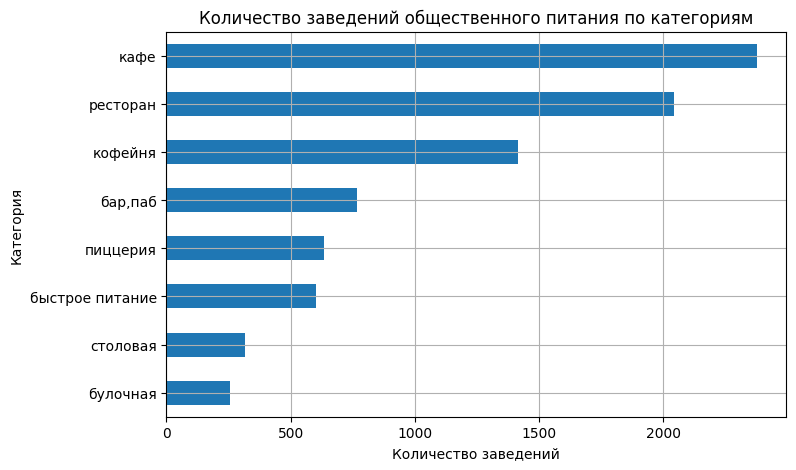

In [22]:
# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(8, 5))

# Строим горизонтальную столбчатую диаграмму с помощью pandas через plot(kind='barh')
rest_df['category'].value_counts(ascending=True).plot(
                   kind='barh', # Тип графика - горизонтальная столбчатая диаграмма
                   legend=False, # Выключаем легенду
                   title='Количество заведений общественного питания по категориям'
)

# Настраиваем оформление графика
plt.xlabel('Количество заведений')
plt.ylabel('Категория')
# Добавляем сетку графика
plt.grid()

# Выводим график
plt.show()

Чаще всего встречаются кафе – 28,3%, на вторром месте рестораны – 24,3%, меньше всего булочных и столовых.

**Административные районы Москвы**

In [23]:
# Выведим уникальные значения районов

print('Количество районов:', rest_df['district'].nunique())
rest_df['district'].value_counts()

Количество районов: 9


district
Центральный административный округ         2242
Северный административный округ             898
Южный административный округ                892
Северо-Восточный административный округ     890
Западный административный округ             850
Восточный административный округ            798
Юго-Восточный административный округ        714
Юго-Западный административный округ         709
Северо-Западный административный округ      409
Name: count, dtype: int64

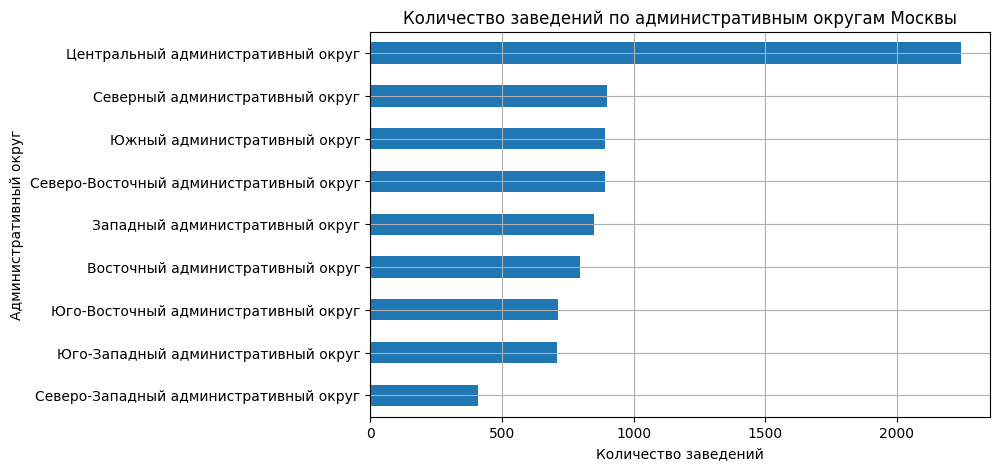

In [24]:
# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(8, 5))

# Строим горизонтальную столбчатую диаграмму с помощью pandas через plot(kind='barh')
rest_df['district'].value_counts(ascending=True).plot(
                   kind='barh', # Тип графика - горизонтальная столбчатая диаграмма
                   legend=False, # Выключаем легенду
                   title='Количество заведений по административным округам Москвы'
)

# Настраиваем оформление графика
plt.xlabel('Количество заведений')
plt.ylabel('Административный округ')
# Добавляем сетку графика
plt.grid()

# Выводим график
plt.show()

В данных представлено 9 административных округов Москвы.

В топе Центральный административный округ — 2242 заведения.

Остальные восемь округов распределены равномерно — от 409 (Северо-Западный) до 898 (Северный) заведений.

**Категории заведений в Центральном административном округе**

Отдельно посмотрим, как распределены категории заведений внутри ЦАО — самого насыщенного заведениями округа.

In [25]:
cao = rest_df[rest_df['district'] == 'Центральный административный округ']
print('Заведений в ЦАО:', cao.shape[0])
cao['category'].value_counts()

Заведений в ЦАО: 2242


category
ресторан           670
кафе               464
кофейня            428
бар,паб            364
пиццерия           113
быстрое питание     87
столовая            66
булочная            50
Name: count, dtype: int64

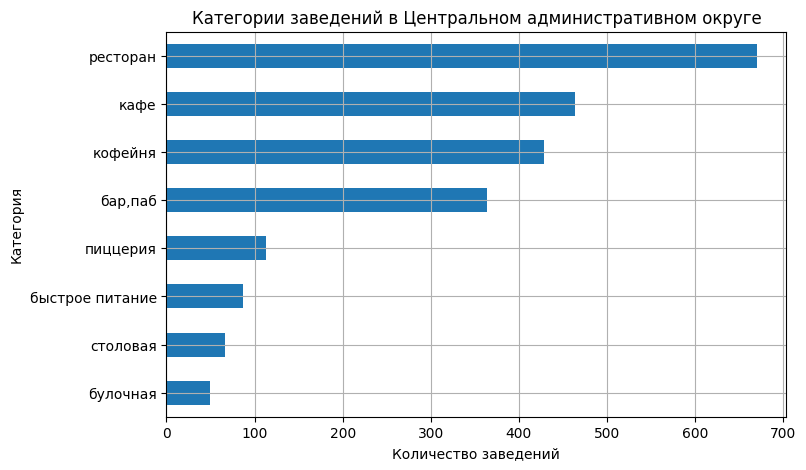

In [26]:
# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(8, 5))

# Строим горизонтальную столбчатую диаграмму с помощью pandas через plot(kind='barh')
cao['category'].value_counts(ascending=True).plot(
                   kind='barh', # Тип графика - горизонтальная столбчатая диаграмма
                   legend=False, # Выключаем легенду
                   title='Категории заведений в Центральном административном округе'
)

# Настраиваем оформление графика
plt.xlabel('Количество заведений')
plt.ylabel('Категория')
# Добавляем сетку графика
plt.grid()

# Выводим график
plt.show()

В ЦАО представлены все 8 категорий, но их соотношение заметно отличается от общей статистики по городу: 

здесь лидирует ресторан (670), а не кафе, как по городу в целом,
кафе (464) и кофейня (428) далее, а доля бар,паб (364, ≈ 16% от всех заведений округа) заметно выше, чем по городу в целом (9.1%). Это ожидаемо для центра города.

**Сетевые и несетевые заведения**

Столбец `chain` равен 1, если заведение является частью сети, и 0 — если нет.

Несетевых заведений больше, чем сетевых: 5198 (61.9%) и 3204 (38.1%).

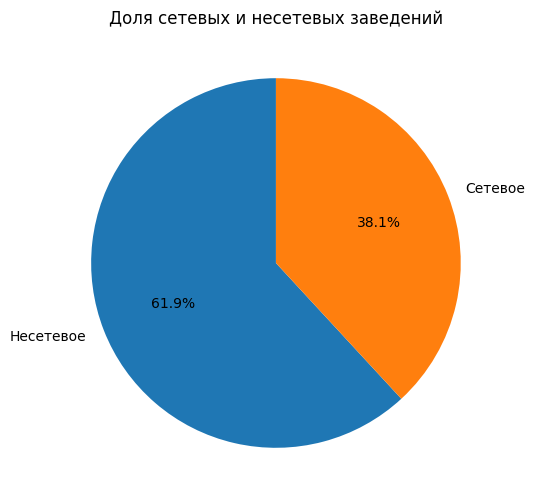

In [27]:
# Считаем количество сетевых и несетевых заведений
chain_counts = rest_df['chain'].map({0: 'Несетевое', 1: 'Сетевое'}).value_counts()

# Строим круговую диаграмму
chain_counts.plot(kind='pie', autopct='%1.1f%%', figsize=(6, 6), startangle=90)

plt.title('Доля сетевых и несетевых заведений')
plt.ylabel('')  # Убираем подпись оси Y
plt.show()

**Доля сетевых заведений по категориям**

In [28]:
# Для каждой категории считаем долю сетевых заведений (среднее значение `chain`)

chain_share = (rest_df.groupby('category')['chain'].mean() * 100).round(1).sort_values(ascending=False)
chain_share

category
булочная           61.3
пиццерия           52.1
кофейня            51.0
быстрое питание    38.5
ресторан           35.7
кафе               32.8
столовая           27.9
бар,паб            22.1
Name: chain, dtype: float64

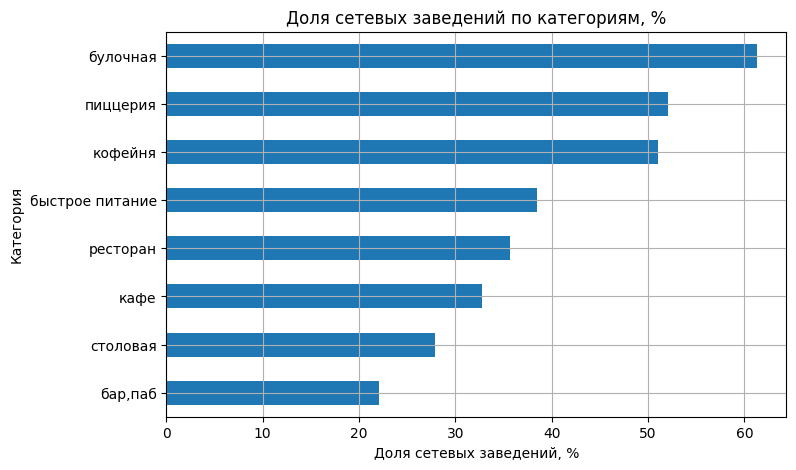

In [29]:
# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(8, 5))

# Строим горизонтальную столбчатую диаграмму с помощью pandas через plot(kind='barh')
chain_share.sort_values().plot(
                   kind='barh', # Тип графика - горизонтальная столбчатая диаграмма
                   legend=False, # Выключаем легенду
                   title='Доля сетевых заведений по категориям, %'
)

# Настраиваем оформление графика
plt.xlabel('Доля сетевых заведений, %')
plt.ylabel('Категория')
# Добавляем сетку графика
plt.grid()

# Выводим график
plt.show()

Чаще всего сетевыми оказываются `булочная` (61.3%), далее `пиццерия` (52.1%) и `кофейня` (51.0%) — это логично, т.к. для таких категорий легче всего настроить франшизу. Меньше всего сетевых заведений — `бар,паб` (22.1%) и `столовая` (27.9%): это форматы, где чаще встречаются авторская концепция или местная специфика, сложнее расщиряться. `Ресторан` и `кафе` занимают среднее положение (35.7% и 32.8%).

## Анализ посадочных мест в заведениях

In [30]:
# Изучаем статистические показатели столбца seats

seats_stats = rest_df['seats'].describe(). round (1)
print(seats_stats)

# Изучаем статистические показатели столбца seats по категориям заведений

seats_by_cat = rest_df.groupby('category')['seats'].describe(). round (1)
print(seats_by_cat)

count    4792.0
mean      108.4
std       122.8
min         0.0
25%        40.0
50%        75.0
75%       140.0
max      1288.0
Name: seats, dtype: float64
                  count   mean    std  min   25%   50%    75%     max
category                                                             
бар,паб           468.0  124.5  145.0  0.0  48.0  82.5  150.0  1288.0
булочная          148.0   89.4   97.7  0.0  25.0  50.0  120.0   625.0
быстрое питание   349.0   98.9  106.6  0.0  28.0  65.0  140.0  1040.0
кафе             1217.0   97.4  117.9  0.0  35.0  60.0  120.0  1288.0
кофейня           751.0  111.2  127.8  0.0  40.0  80.0  144.0  1288.0
пиццерия          427.0   94.5  112.3  0.0  30.0  55.0  120.0  1288.0
ресторан         1268.0  121.9  123.8  0.0  48.0  86.0  150.0  1288.0
столовая          164.0   99.8  123.0  0.0  40.0  75.5  117.0  1200.0


In [31]:
print('Количество заведений с seats = 0', (rest_df['seats']==0).sum())

print('Распределение seats = 0 по категориям заведений:')
print(rest_df.loc[rest_df['seats']==0, 'category'].value_counts())

Количество заведений с seats = 0 136
Распределение seats = 0 по категориям заведений:
category
кафе               44
кофейня            24
ресторан           20
быстрое питание    18
булочная           11
пиццерия           10
столовая            5
бар,паб             4
Name: count, dtype: int64


Распределение `seats` сильно скошено вправо: медиана — 75 мест, среднее — 108 (стандартное отклонение 123 — близко к среднему). Аномальные значения: минимум – 0, максимум — 1288.

136 заведений (2.8%) с seats – 0. 
Нулевые значения (136 заведений) распределены по всем категориям, больше всего среди кафе, кофеен, ресторанов и фастфуда — возможно, это не ошибка, а формат работы без посадочных мест на вынос.

In [32]:
# Проверям на аномально высокие значения

rest_df[rest_df['seats']>400][['name','category','address','seats']].sort_values('seats', ascending=False).head(25)

,name,category,address,seats
6053,Loft-cafe академия,кафе,"Москва, проспект Вернадского, 84, стр. 1",1288.0
6551,Ян Примус,ресторан,"Москва, проспект Вернадского, 121, корп. 1",1288.0
147,One Price Coffee,кофейня,"Москва, проспект Вернадского, 84, стр. 1",1288.0
5383,Яндекс Лавка,ресторан,"Москва, проспект Вернадского, 51, стр. 1",1288.0
3632,Точка,кафе,"Москва, проспект Вернадского, 84, стр. 1",1288.0
353,Alternative coffee,кофейня,"Москва, проспект Вернадского, 41, стр. 1",1288.0
8214,Японская кухня,ресторан,"Москва, проспект Вернадского, 121, корп. 1",1288.0
2905,Мюнгер,пиццерия,"Москва, проспект Вернадского, 97, корп. 1",1288.0
8277,DelonixCafe,ресторан,"Москва, проспект Вернадского, 94, корп. 1",1288.0
3211,Пивной ресторан,"бар,паб","Москва, проспект Вернадского, 121, корп. 1",1288.0


Аномально высокие значения на одном и том же адресе у нескольких разных заведений с одинаковым числом мест (например, 4 заведения на Измайловском шоссе, 71, корп.А – 1040 мест). Возможно число мест указано для фудкорта в целом и продублировано на каждое заведение внутри него, а не для каждого отдельного заведения.

Из-за такой асимметрии распределения **медиана** — более надёжная характеристика типичного числа мест, чем среднее.

**Анализ количества посадчных мест**

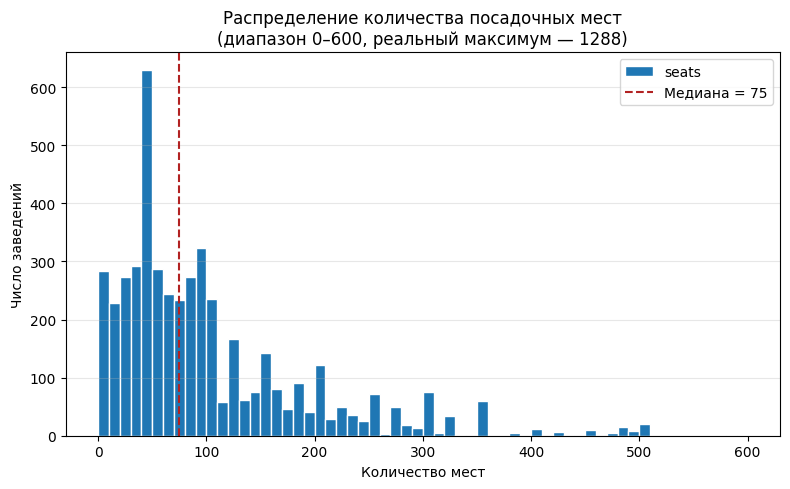

In [33]:
# Распределение количества посадочных мест (диапозон до 600, без аномалий)

median_seats = rest_df['seats'].median()

rest_df['seats'].plot(kind='hist', bins=60, range=(0, 600),
                       title='Распределение количества посадочных мест\n(диапазон 0–600, реальный максимум — 1288)',
                       xlabel='Количество мест',
                       ylabel='Число заведений',
                       color='#1f77b4', edgecolor='white', figsize=(8, 5))
plt.axvline(median_seats, color='firebrick', linestyle='--', label=f'Медиана = {int(median_seats)}')
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

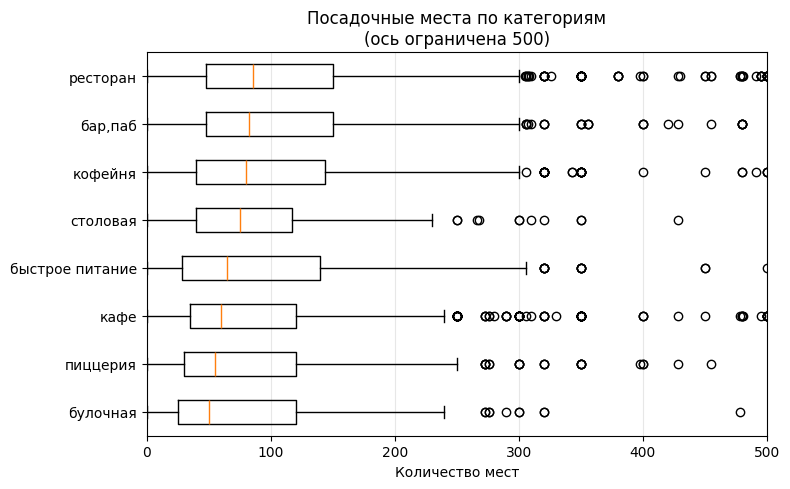

In [34]:
# Распределение посадочных мест по категориям (усы обрезаны до 500)

order = rest_df.groupby('category')['seats'].median().sort_values(ascending=False).index
data = [rest_df.loc[rest_df['category'] == cat, 'seats'].dropna() for cat in order]

plt.figure(figsize=(8, 5))
plt.boxplot(data, vert=False)
plt.yticks(range(1, len(order) + 1), order)
plt.gca().invert_yaxis()  # Категория с наибольшей медианой сверху
plt.xlim(0, 500)
plt.title('Посадочные места по категориям\n(ось ограничена 500)')
plt.xlabel('Количество мест')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

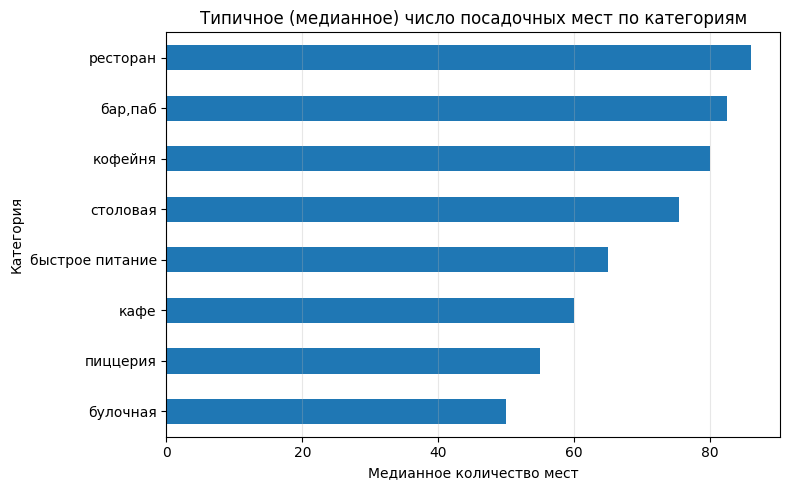

In [35]:
seats_median = rest_df.groupby('category')['seats'].median().round(1)

sorted_median = seats_median.sort_values()

sorted_median.plot(kind='barh',
                    title='Типичное (медианное) число посадочных мест по категориям',
                    legend=False,
                    xlabel='Медианное количество мест',
                    ylabel='Категория',
                    figsize=(8, 5))
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

**Типичное количество мест по категориям (медиана)** 

Больше всего мест обычно в ресторанах (86), барах/пабах (82.5) и кофейнях (80) — это крупные форматы с полноценным залом, где люди проводят дольше времени. Меньше всего — в пиццериях (55) и булочных (50), которые работают как фастфуд или навынос, и люди не задерживаются долго. Кафе (60), столовые (75.5) и заведения быстрого питания (65) — посередине.

## Анализ рейтинга заведений

Столбец `rating` — рейтинг заведения на Яндекс Картах от 1 до 5. Проверим общее распределение, затем сравним средние рейтинги между категориями.

In [36]:
print(rest_df['rating'].describe())
print()
print('Пропусков в rating:', rest_df['rating'].isna().sum())
print('rating = 0:', (rest_df['rating']==0).sum())
print('Уникальные значения rating (первые 20):', sorted(rest_df['rating'].dropna().unique())[:20])

count    8402.000000
mean        4.230017
std         0.470320
min         1.000000
25%         4.100000
50%         4.300000
75%         4.400000
max         5.000000
Name: rating, dtype: float64

Пропусков в rating: 0
rating = 0: 0
Уникальные значения rating (первые 20): [np.float64(1.0), np.float64(1.1), np.float64(1.2), np.float64(1.3), np.float64(1.4), np.float64(1.5), np.float64(1.6), np.float64(1.7), np.float64(1.8), np.float64(1.9), np.float64(2.0), np.float64(2.1), np.float64(2.2), np.float64(2.3), np.float64(2.4), np.float64(2.5), np.float64(2.6), np.float64(2.7), np.float64(2.8), np.float64(2.9)]


Пропусков и нулей в `rating` нет — оценка выставлена для всех 8402 заведений. Распределение смещено влево (к высоким оценкам): медиана 4.3, среднее 4.23, межквартильный размах узкий — от 4.1 до 4.4. Формально минимум — 1.0, но такие низкие оценки редки: это заведения с единичными негативными отзывами, а не типичная картина.

In [37]:
rating_by_cat = rest_df.groupby('category')['rating'].agg(['count', 'mean', 'median', 'std', 'min', 'max']).round(2)
rating_by_cat = rating_by_cat.sort_values('mean', ascending=False)
print('Размах средних рейтингов по категориям:', round(rating_by_cat['mean'].max() - rating_by_cat['mean'].min(), 2))
print('Среднее std внутри категорий:', round(rating_by_cat['std'].mean(), 2))
rating_by_cat

Размах средних рейтингов по категориям: 0.34
Среднее std внутри категорий: 0.43


,count,mean,median,std,min,max
category,,,,,,
"бар,паб",765,4.39,4.4,0.38,1.1,5.0
пиццерия,633,4.30,4.3,0.34,1.0,5.0
ресторан,2041,4.29,4.3,0.41,1.0,5.0
кофейня,1413,4.28,4.3,0.37,1.4,5.0
булочная,256,4.27,4.3,0.39,1.3,5.0
столовая,315,4.21,4.3,0.45,1.0,5.0
кафе,2376,4.12,4.2,0.57,1.0,5.0
быстрое питание,603,4.05,4.2,0.56,1.1,5.0


Средние рейтинги по категориям лежат в диапазоне 4.05-4.39 (размах — 0.34 балла), при этом среднее стандартное отклонение внутри каждой категории — 0.43, то есть больше самого размаха между категориями. Отдельные заведения внутри одной категории отличаются друг от друга сильнее, чем заведения разных категорий отличаются между собой. На рейтинг влияют индивидуальные особенности самого заведения (его сервис, кухня, атмосфера и т.д.), а не то, к какому типу оно относится.

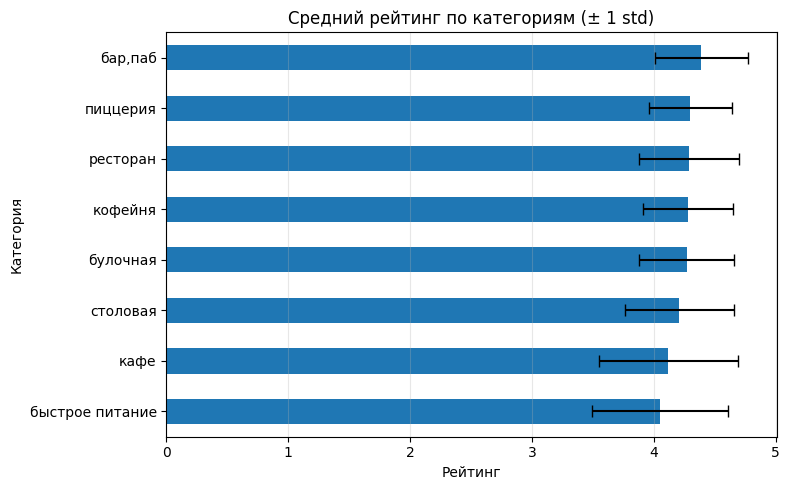

In [38]:
order_asc = rating_by_cat.sort_values('mean').index

rating_by_cat.loc[order_asc, 'mean'].plot(kind='barh', xerr=rating_by_cat.loc[order_asc, 'std'],
                                           title='Средний рейтинг по категориям (± 1 std)',
                                           xlabel='Рейтинг',
                                           ylabel='Категория',
                                           color='#1f77b4', capsize=4, figsize=(8, 5))
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

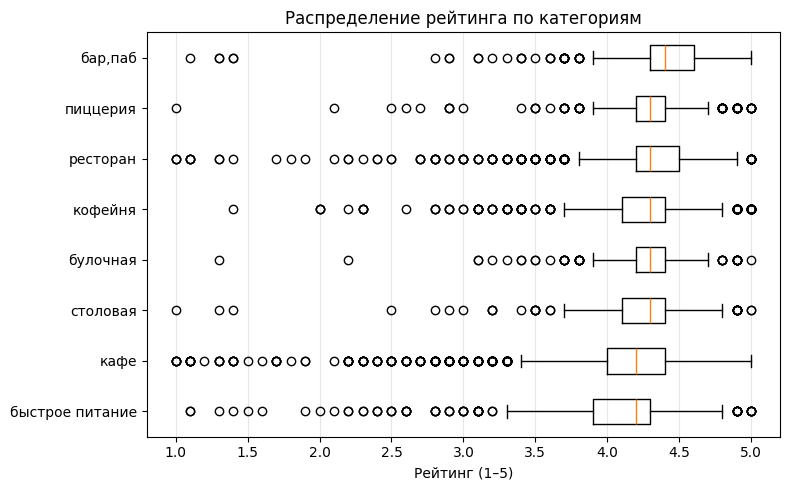

In [39]:
# Визуализируем распределение рейтинга по категориям

order_asc = rating_by_cat.sort_values('mean').index
data = [rest_df.loc[rest_df['category'] == cat, 'rating'].dropna() for cat in order_asc]

plt.figure(figsize=(8, 5))
# подписи задаём отдельно — так код работает и в старых, и в новых версиях matplotlib
plt.boxplot(data, vert=False)
plt.yticks(range(1, len(order_asc) + 1), order_asc)
plt.title('Распределение рейтинга по категориям')
plt.xlabel('Рейтинг (1–5)')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

**Вывод** 

Заведения общепита в Москве имеют в среднем похожий рейтинг независимо от категории. Небольшой, но устойчивый паттерн всё же есть: бары/пабы, пиццерии, рестораны и кофейни оценены чуть выше (в среднем 4.28-4.39), а кафе и заведения быстрого питания — чуть ниже (4.05-4.12). Разница между лучшей и худшей категорией — всего 0.34 балла, что примерно в 1.3 раза меньше типичного разброса оценок внутри одной категории, поэтому тип заведения — слабый предиктор рейтинга: качество отдельного заведения определяет оценку сильнее, чем его категория. У всех категорий медиана рейтинга лежит в узком диапазоне примерно 4.2–4.4.

## Корреляция рейтинга с другими признаками

Проверим, с какими характеристиками заведения рейтинг связан сильнее всего: категория, район, статус сетевого заведения, количество мест, ценовая категория, круглосуточный режим работы. Так как признаки смешанные (категориальные и количественные), используем коэффициент **phik** — он одинаково корректно работает и с числами, и с категориями. Сначала посмотрим на сами эти признаки.

In [40]:
print(rest_df.dtypes)
print()
print(rest_df['price'].value_counts(dropna=False))
print()
print(rest_df['chain'].value_counts(dropna=False))
print()
print(rest_df['district'].value_counts(dropna=False))
print()
print(rest_df['hours'].value_counts(dropna=False).head(20))

id                    object
name                  object
category              object
address               object
district              object
hours                 object
rating               float64
chain                   int8
seats                float64
price                 object
avg_bill              object
middle_avg_bill      float64
middle_coffee_cup    float64
is_24_7                 bool
dtype: object

price
не указано       5087
средние          2117
выше среднего     564
высокие           478
низкие            156
Name: count, dtype: int64

chain
0    5198
1    3204
Name: count, dtype: int64

district
Центральный административный округ         2242
Северный административный округ             898
Южный административный округ                892
Северо-Восточный административный округ     890
Западный административный округ             850
Восточный административный округ            798
Юго-Восточный административный округ        714
Юго-Западный административный округ   

In [41]:
print(rest_df['is_24_7'].value_counts())
try:
        import phik
        print('phik version:', phik.__version__)
except ImportError as e:
        print('нет phik:', e)

is_24_7
False    7672
True      730
Name: count, dtype: int64
phik version: 0.12.5


In [42]:
cols_for_corr = ['category', 'district', 'chain', 'seats', 'price', 'is_24_7', 'rating']

correlation_matrix = rest_df[cols_for_corr].phik_matrix(interval_cols=['seats', 'rating'])

print('Корреляционная матрица с коэффициентом phi_k для переменной rating')
correlation_matrix.loc[correlation_matrix.index != 'rating'][['rating']].sort_values(by='rating', ascending=False)

Корреляционная матрица с коэффициентом phi_k для переменной rating


,rating
price,0.281253
district,0.200761
category,0.189677
is_24_7,0.150365
chain,0.107973
seats,0.000000


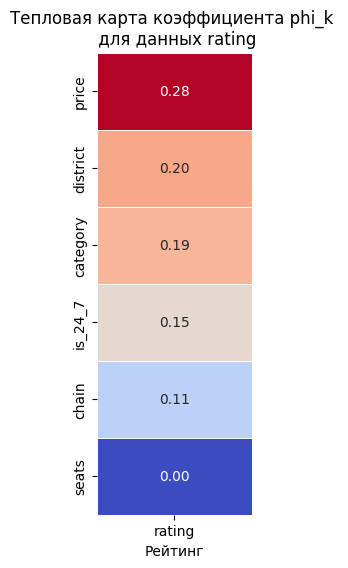

In [43]:
# Строим тепловую карту

import seaborn as sns
plt.figure(figsize=(2, 6))

# Сохраняем матрицу корреляции признака rating с другими признаками клиента
data_heatmap = correlation_matrix.loc[correlation_matrix.index != 'rating'][['rating']].sort_values(by='rating', ascending=False)
sns.heatmap(data_heatmap,
            annot=True, # Отображаем численные значения в ячейках карты
            fmt='.2f', # Форматируем значения корреляции: два знака после точки
            cmap='coolwarm', # Устанавливаем цветовую гамму от красного (макс. значение) к синему
            linewidths=0.5, # Форматируем линию между ячейками карты
            cbar=False # Отключаем цветовую шкалу
           )

# Добавляем заголовок и подпись по оси Х
plt.title('Тепловая карта коэффициента phi_k \n для данных rating')
plt.xlabel('Рейтинг')

# Выводим график
plt.show()

Сильнее всего с рейтингом связана **ценовая категория** (phi_k = 0.28), за ней идут район (0.20) и категория заведения (0.19). Признак круглосуточной работы даёт умеренную связь (0.15), сетевой статус — слабую (0.11), а число посадочных мест никак не связано с рейтингом (0.00) — размер зала не влияет на то, как заведение оценивают. 

### Проверка самой сильной связи: рейтинг и ценовая категория

In [44]:
price_order = ['не указано', 'низкие', 'средние', 'выше среднего', 'высокие']
rating_by_price = rest_df.groupby('price', observed=True)['rating'].agg(['count', 'mean', 'median', 'std']).round(2)
rating_by_price = rating_by_price.loc[price_order]
rating_by_price

,count,mean,median,std
price,,,,
не указано,5087,4.17,4.3,0.55
низкие,156,4.17,4.2,0.37
средние,2117,4.30,4.3,0.30
выше среднего,564,4.39,4.4,0.22
высокие,478,4.44,4.4,0.31


**Проверям связь рейтинга с ценой**

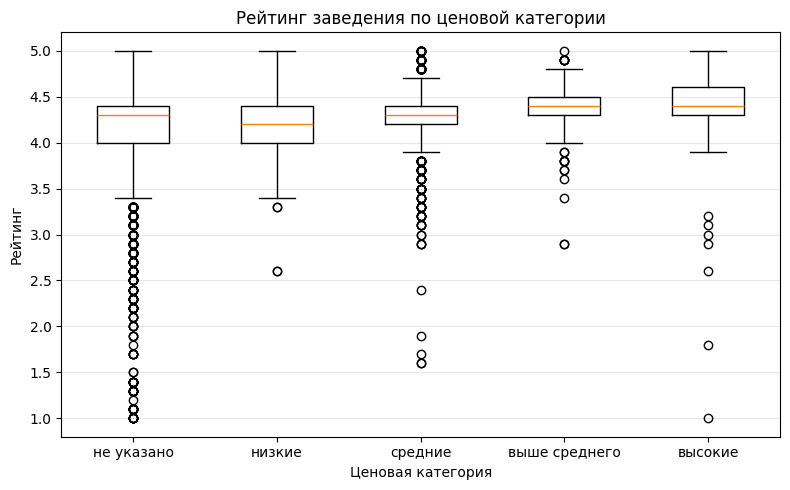

In [45]:
# Визуализируем распределение рейтинга по ценовым категориям

data = [rest_df.loc[rest_df['price'] == p, 'rating'].dropna() for p in price_order]

plt.figure(figsize=(8, 5))
# подписи задаём отдельно — так код работает и в старых, и в новых версиях matplotlib
plt.boxplot(data)
plt.xticks(range(1, len(price_order) + 1), price_order)
plt.title('Рейтинг заведения по ценовой категории')
plt.ylabel('Рейтинг')
plt.xlabel('Ценовая категория')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

**Вывод** 

Прямой линейной связи между ценой и рейтингом нет, хотя у категории высоких цен меньше всего выбросов, самая высокая медиана и ящик смещен выше остальных.

Заведения без указанной ценовой категории — более низкокачественные заведения, судя по большому количеству выбросов (низких оценок). У средних тоже видна заметная цепочка выбросов от ~2.9 до 3.9 — больше, чем у низких и выше среднего. Возможно, это связано с тем, что категория средние – самая многочисленная группа, поэтому там и абсолютное число выбросов выше.

Отсутствие указанной цены имеет сильную связь с риском низкого рейтинга и большим разбросом качества, что может быть полезно, например, для рекомендательной системы или фильтрации проблемных заведений.

## Топ-15 популярных сетей Москвы

Группируем данные по названию заведения среди сетевых точек (`chain == 1`), считаем число точек и средний рейтинг, смотрим, к каким категориям относятся самые крупные сети.

In [46]:
# Группируем по названию сети

chain_df = rest_df[rest_df['chain'] == 1]

def get_mode(s): # если мод несколько, берётся первая по порядку
    return s.mode().iloc[0]

name_stats = chain_df.groupby('name').agg(
        points_count=('name', 'size'),
        rating_mean=('rating', 'mean'),
        category_mode=('category', get_mode),
        category_nunique=('category', 'nunique') # проверка и дополнение к моде
).round(2)

# Выводим топ 15

top15 = name_stats.sort_values('points_count', ascending=False).head(15)
top15

,points_count,rating_mean,category_mode,category_nunique
name,,,,
Шоколадница,120,4.18,кофейня,2
Домино'с Пицца,76,4.17,пиццерия,1
Додо Пицца,74,4.29,пиццерия,1
One Price Coffee,71,4.06,кофейня,1
Яндекс Лавка,69,3.87,ресторан,1
Cofix,65,4.08,кофейня,1
Prime,50,4.12,ресторан,2
Хинкальная,44,4.32,кафе,5
КОФЕПОРТ,42,4.15,кофейня,1


In [47]:
print('Категории среди топ-15 сетей (по самой частой категории у каждой сети):')
print(top15['category_mode'].value_counts())
print()
print('Сети, у которых точки числятся в нескольких разных категориях:')
print(top15.loc[top15['category_nunique'] > 1, ['points_count', 'category_mode', 'category_nunique']])

Категории среди топ-15 сетей (по самой частой категории у каждой сети):
category_mode
кофейня     5
кафе        4
ресторан    3
пиццерия    2
булочная    1
Name: count, dtype: int64

Сети, у которых точки числятся в нескольких разных категориях:
             points_count category_mode  category_nunique
name                                                     
Шоколадница           120       кофейня                 2
Prime                  50      ресторан                 2
Хинкальная             44          кафе                 5
Теремок                38      ресторан                 2
Чайхана                37          кафе                 3
CofeFest               32       кофейня                 2
Буханка                32      булочная                 3
Му-Му                  27          кафе                 7


Среди топ-15 самых крупных сетей Москвы:

1 место – категория **кофейня** – 5 сетей из 15 и **кафе** – 4, далее ресторан – 3, пиццерия – 2, булочная – 1. 

Лидер по числу точек — Шоколадница – 120 точек, 2 место Домино'с Пицца – 76.

**Важное наблюдение:** 

У 8 из 15 сетей точки числятся сразу в нескольких разных категориях: My-My — в 7, у Хинкальной — в 5. 

Для крупных узнаваемых брендов вроде Шоколадницы это, скорее всего, погрешность разметки отдельных точек. А у названий Хинкальная, Чайхана или My-My высокая category_nunique может значить ошибку, что под одним именем в датасете, вероятно, объединены несвязанные заведения с похожим названием, а не одна настоящая франшиза — это стоит иметь в виду при интерпретации их рейтинга и числа точек.

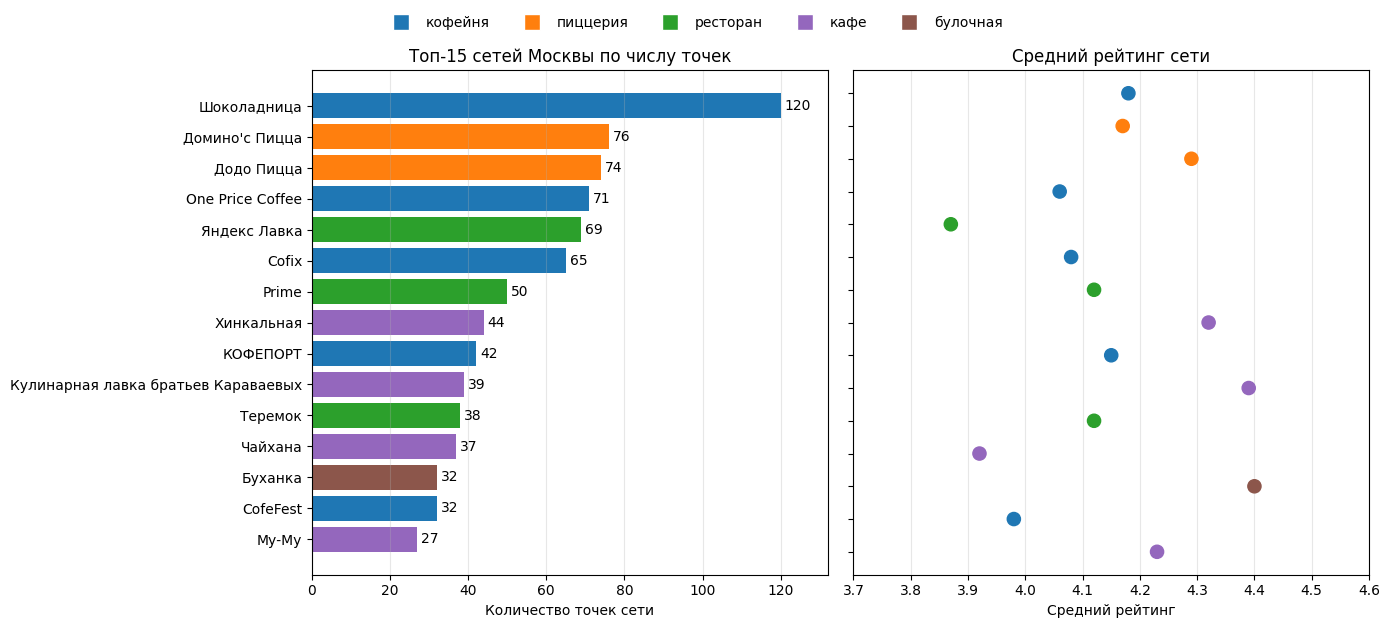

In [48]:
category_colors = {'кофейня': '#1f77b4', 'пиццерия': '#ff7f0e', 'ресторан': '#2ca02c', 'кафе': '#9467bd', 'булочная': '#8c564b'}

top15_asc = top15.sort_values('points_count')
bar_colors = [category_colors[c] for c in top15_asc['category_mode']]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

ax = axes[0]
bars = ax.barh(top15_asc.index, top15_asc['points_count'], color=bar_colors)
for i, v in enumerate(top15_asc['points_count']):
    ax.text(v + 1, i, v, va='center')
ax.set_xlim(0, top15_asc['points_count'].max() * 1.1)  # место под подпись у самого длинного столбца
ax.set_title('Топ-15 сетей Москвы по числу точек')
ax.set_xlabel('Количество точек сети')
ax.grid(axis='x', alpha=0.3)

ax = axes[1]
ax.scatter(top15_asc['rating_mean'], top15_asc.index, color=bar_colors, s=90, zorder=3)
ax.set_title('Средний рейтинг сети')
ax.set_xlabel('Средний рейтинг')
ax.set_xlim(3.7, 4.6)
ax.grid(axis='x', alpha=0.3)
ax.set_yticklabels([])
ax.set_ylabel('')

legend_handles = [plt.Line2D([0], [0], marker='s', color='w', markerfacecolor=color, markersize=12, label=cat) for cat, color in category_colors.items()]
fig.legend(handles=legend_handles, loc='upper center', ncol=5, bbox_to_anchor=(0.5, 1.05), frameon=False)

plt.tight_layout()
plt.show()

**Вывод** 

Популярность сети (число точек) и её средний рейтинг практически не связаны. 

1 место — Шоколадница (120 точек), Домино'с Пицца (76) и Додо Пицца (74) — средний уровень (4.17–4.29). 

При этом самые высокие рейтинги в топ-15 у заметно менее крупных сетей: Буханка (4.40, булочная, 32 точки) и Кулинарная лавка братьев Караваевых (4.39, кафе, 39 точек), а самый низкий — у Яндекс Лавки (3.87, ресторан, 69 точек). 

Это подтверждает вывод из корреляционного анализа: сетевой статус и масштаб сети слабо влияют на рейтинг заведения.

## Средний чек и удалённость от центра Москвы

Распределение среднего чека заведения (`middle_avg_bill`) в зависимости от административного округо, отдельно сравним Центральный административный округ (ЦАО) с остальными округами, чтобы найти зависимостть между удалённостью округа от центра и уровнем цен.

In [49]:
print('Пропуски в middle_avg_bill:', rest_df['middle_avg_bill'].isna().sum(), 'из', len(rest_df))
print()

print(rest_df['middle_avg_bill'].describe())
print()
print('Распределение количества заведений по округам:')
print(rest_df['district'].value_counts())

print('Доля пропусков middle_avg_bill по округам:')
missing_share = (rest_df['middle_avg_bill'].isna().groupby(rest_df['district']).mean() * 100).round(1).sort_values(ascending=False)
print(missing_share)
print()

Пропуски в middle_avg_bill: 5253 из 8402

count     3149.000000
mean       958.053668
std       1009.732845
min          0.000000
25%        375.000000
50%        750.000000
75%       1250.000000
max      35000.000000
Name: middle_avg_bill, dtype: float64

Распределение количества заведений по округам:
district
Центральный административный округ         2242
Северный административный округ             898
Южный административный округ                892
Северо-Восточный административный округ     890
Западный административный округ             850
Восточный административный округ            798
Юго-Восточный административный округ        714
Юго-Западный административный округ         709
Северо-Западный административный округ      409
Name: count, dtype: int64
Доля пропусков middle_avg_bill по округам:
district
Юго-Восточный административный округ       72.8
Восточный административный округ           67.4
Юго-Западный административный округ        66.9
Северо-Восточный административный

In [50]:
print('Топ-10 самых высоких средних чеков:')
print(rest_df.nlargest(10, 'middle_avg_bill')[['name', 'category', 'district', 'middle_avg_bill']])

Топ-10 самых высоких средних чеков:
                          name         category  \
230                       Кафе         ресторан   
4569                   Чойхона          бар,паб   
5949                     Гости         ресторан   
488               White Rabbit         ресторан   
2294  800°с Contemporary Steak         ресторан   
6686                     Марио         ресторан   
4248                     Чайка         ресторан   
3661       Кантинетта Антинори         ресторан   
6648           Крошка Картошка  быстрое питание   
7719         Lucky Izakaya Bar          бар,паб   

                                district  middle_avg_bill  
230         Южный административный округ          35000.0  
4569     Северный административный округ          11000.0  
5949    Восточный административный округ          10000.0  
488   Центральный административный округ           7250.0  
2294  Центральный административный округ           7000.0  
6686  Центральный административный округ  

**Вывод**

Значение `middle_avg_bill` заполнено только у 3149 из 8402 заведений (37.5%), причём в ЦАО пропусков заметно меньше (52.7%), чем в остальных округах (61.6–66.9%) — то есть сравнение опирается на неполную и не вполне однородную выборку. Распределение сильно скошено вправо (медиана 750 ₽, среднее 958 ₽, максимум 35 000 ₽) из-за единичных дорогих ресторанов, поэтому для сравнения округов лучше ориентироваться на медиану, а не на среднее.

In [51]:
# Ранжируем округа по цене среднего чека, сортируем по медиане

bill_by_district = rest_df.groupby('district')['middle_avg_bill'].agg(count='count', median='median', mean='mean', std='std').round(1)
bill_by_district = bill_by_district.sort_values('median', ascending=False)
bill_by_district

,count,median,mean,std
district,,,,
Западный административный округ,306,1000.0,1053.2,779.0
Центральный административный округ,1060,1000.0,1191.1,920.0
Северо-Западный административный округ,157,700.0,822.2,595.1
Северный административный округ,322,650.0,928.0,912.6
Юго-Западный административный округ,235,600.0,792.6,559.2
Восточный административный округ,260,575.0,820.6,850.9
Северо-Восточный административный округ,301,500.0,716.6,591.2
Южный административный округ,314,500.0,834.4,2008.6
Юго-Восточный административный округ,194,450.0,654.1,566.8


У Центрального округа заведений почти в 3.5 раза больше, чем в Западном (1060 против 306) — это самая многочисленная выборка в таблице, значит, его показатели статистически наиболее надёжны. При этом у Центрального выше и mean, и std — значит, там больше по-настоящему дорогих заведений, которые «тянут» среднее вверх сильнее, чем в Западном округе, при той же медиане.

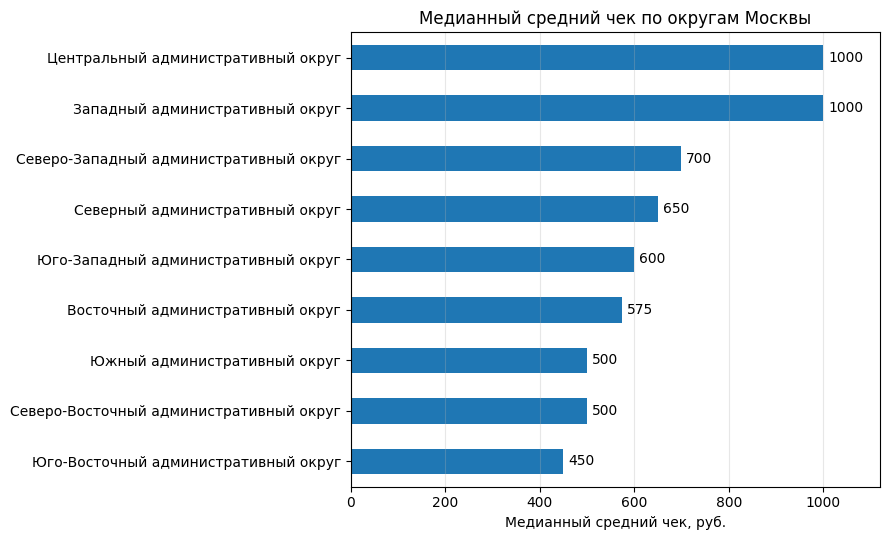

In [52]:
# Визуализируем распределение медианного среднего чека по округам

order_asc = bill_by_district.sort_values('median').index
medians_asc = bill_by_district.loc[order_asc, 'median']
medians_asc.plot(kind='barh',
                 title='Медианный средний чек по округам Москвы',
                 figsize=(9, 5.5))
for i, v in enumerate(medians_asc):
    plt.text(v + 10, i, f'{v:.0f}', va='center')
plt.xlabel('Медианный средний чек, руб.')
plt.ylabel('')
plt.xlim(0, medians_asc.max() * 1.12)
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

Средний чек в ЦАО заметно выше, чем в остальной Москве: медиана 1000 ₽ против 600 ₽ (в 1.7 раза). Медианный чек снижается от 1000 ₽ в ЦАО и ЗАО до 450–500 ₽ в отдалённых от центра ЮВАО, СВАО и ЮАО — это согласуется с гипотезой, что удалённость от центра связана с более демократичными ценами.

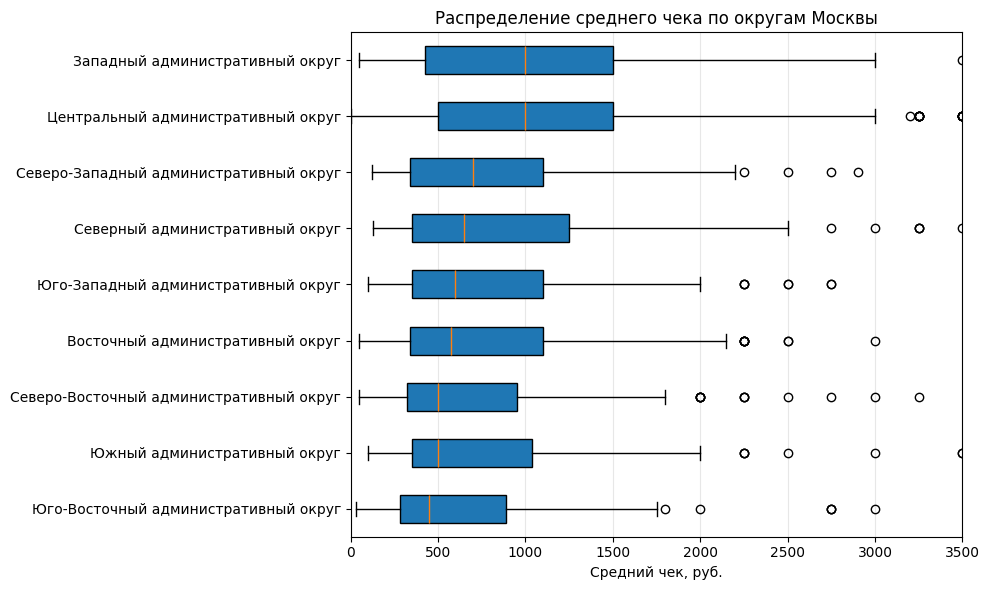

In [54]:
# Визуализируем распределение среднего чека по округам

order_desc = bill_by_district.index
box_data = [rest_df.loc[rest_df['district'] == d, 'middle_avg_bill'].dropna() for d in order_desc]

plt.figure(figsize=(10, 6))
bp = plt.boxplot(box_data, vert=False, patch_artist=True)
plt.yticks(range(1, len(order_desc) + 1), order_desc)

plt.gca().invert_yaxis()
plt.xlim(0, 3500)
plt.title('Распределение среднего чека по округам Москвы')
plt.xlabel('Средний чек, руб.')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

Медианы (оранжевые линии) убывают сверху вниз.

У Западного и Центрального АО ящики самые широкие (от 400–500 до 1500 ₽) — наибольшее разнообразие ценовых сегментов: от бюджетных до дорогих заведений в рамках одного округа. Юго-Восточный АО ящик самый узкий и сдвинут влево (примерно 300–900 ₽) — там заведения более однородны по цене и в целом дешевле.

Выбросы справа есть почти у всех округов, кроме Западного и Центрального (у них выбросы фактически сливаются с основным диапазоном, потому что усы и так доходят до 3000). У Северо-Восточного АО заметно больше всего отдельных точек-выбросов (6 штук, до 3500 ₽) — на фоне низкой медианы (500 ₽) встречаются отдельные дорогие заведения.

## Итоговый вывод и рекомендации

### 1. Общий обзор проделанной работы

В ходе исследования были объединены два датасета — `rest_info.csv` (категория, район, рейтинг, сетевой статус, посадочные места) и `rest_price.csv` (ценовые характеристики) — в единый датафрейм `rest_df` из 8402 строк (после удаления 4 неявных дубликатов, найденных при сравнении нормализованных названия и адреса). Пропуски в `hours` и `price` заменены на явные метки «нет данных» / «не указано», а пропуски в `seats`, `avg_bill`, `middle_avg_bill`, `middle_coffee_cup` оставлены как есть, поскольку отражают не ошибку, а особенность заполнения источника. Дополнительно создан признак `is_24_7` — круглосуточный режим работы.

На основе получившегося датафрейма проведён анализ по 8 направлениям: структура категорий заведений, распределение по административным округам Москвы, доля сетевых заведений, количество посадочных мест, рейтинг заведений, корреляция рейтинга с другими признаками (коэффициент phik), топ-15 популярных сетей и зависимость среднего чека от удалённости округа от центра. Каждый раздел сопровождён визуализациями (столбчатые диаграммы, box-plot, гистограммы, тепловая карта корреляции).

### 2. Ответы на исследовательские вопросы

**1. Категории заведений:** в данных представлено 8 категорий, больше всего кафе — 2376 (28.3%) и ресторанов — 2041 (24.3%), далее кофейни — 1413 (16.8%), меньше всего булочных — 256 (3.0%) и столовых — 315 (3.7%), 3 категории (кафе, ресторан, кофейня) формируют почти 70% рынка.

**2. Административные округа: ** в данных 9 округов Москвы, Центральный округ (ЦАО) значительно опережает остальные по числу заведений — 2242 (26.7% всех заведений города), остальные округа распределены более равномерно — от 409 (СЗАО) до 898 (САО). Внутри ЦАО структура распределение категорий: на первом месте рестораны (670), а не кафе (в отличии от картины всего города в целом), заметно выше доля баров/пабов (16% против 9.1% по городу) — типичная картина для центра города с развитой вечерней гастрономией.

**3. Сетевые и несетевые заведения:** в целом по городу преобладают несетевые заведения — 5198 (61.9%) против 3204 сетевых (38.1%). Чаще всего сетевыми оказываются булочные (61.3%), пиццерии (52.1%) и кофейни (51.0%) — форматы с простой бизнес моделью. Реже всего — бары/пабы (22.1%) и столовые (27.9%), где важна локальная или авторская концепция.

**4. Посадочные места:** заполнено только для 4792 заведений (57%), распределение сильно скошено вправо: медиана 75 мест при среднем 108 и максимуме 1288. Обнаружены выбросы: 136 заведений с 0 мест (вероятно формат «навынос», без зала), а также группы заведений на одном адресе с одинаковым аномально большим числом мест (1288) — похоже на фудкорты, где число мест указано на весь фудкорт целиком и продублировано у каждой точки внутри него. Из-за асимметрии распределения медиана надёжнее среднего: типично больше всего мест в ресторанах (86), барах/пабах (82.5) и кофейнях (80), меньше всего — в пиццериях (55) и булочных (50).

**5. Рейтинг заведений:** рейтинг заполнен для всех 8402 заведений, медиана 4.3, среднее 4.23. Средние рейтинги по категориям различаются слабо — от 4.05 (быстрое питание) до 4.39 (бар/паб), размах всего 0.34 балла, что меньше типичного разброса оценок внутри одной категории (std ≈ 0.43). То есть категория заведения — слабый предиктор его рейтинга: индивидуальное качество конкретного заведения значит больше, чем его тип.

**6. Корреляция рейтинга с другими признаками:** по коэффициенту phik сильнее всего с рейтингом связана ценовая категория (0.28), далее район (0.20) и категория заведения (0.19), слабее — круглосуточный режим (0.15) и сетевой статус (0.11); число посадочных мест не связано с рейтингом (0.00). Проверка связи цены и рейтинга подтвердила направление: средний рейтинг растёт от 4.17 у заведений с низкими ценами до 4.44 у заведений с высокими ценами. При этом у заведений без указанной ценовой категории («не указано», 60.6% всех строк) рейтинг ниже среднего и заметно больше разброс (std 0.55) — отсутствие ценовой информации на карте статистически ассоциируется с риском более низкого качества.

**7. Топ-15 популярных сетей:** среди топ-15 сетей по числу точек преобладают кофейни (5 из 15) и кафе (4 из 15). Лидер — Шоколадница (120 точек, рейтинг 4.18), далее Домино'с Пицца (76) и Додо Пицца (74). Масштаб сети и качество практически не связаны: самые высокие рейтинги в топ-15 — у не самых крупных сетей (Буханка — 4.40 при 32 точках, Кулинарная лавка братьев Караваевых — 4.39 при 39 точках), а самый низкий — у Яндекс Лавки (3.87 при 69 точках). У 8 из 15 сетей точки относятся сразу к нескольким разным категориям (максимум — у Му-Му, 7 категорий) — возможно это говорит об объединении в датасете разных заведений с похожим названием под одним именем.

**8. Средний чек и удалённость от центра:** значение `middle_avg_bill` заполнено только для 37.5% заведений, больше всего для ЦАО (пропуски 52.7%), чем на периферии (62–73%), поэтому анализ проводим на неполную выборку. Тем не менее закономерность присутствует: медианный чек снижается по мере удаления от центра — 1000 ₽ в ЦАО и Западном округе, 500–650 ₽ в срединных округах и минимум 450 ₽ в Юго-Восточном округе. Разница между самым дорогим и самым дешёвым округом — более чем в 2 раза. ЦАО и ЗАО также показывают наибольший разброс цен (от бюджетных до премиальных заведений в одном округе), тогда как периферийные округа (особенно ЮВАО) более однородны и низкие по цене.

### 3. Рекомендации


- Открытие заведения в ЦАО обеспечивает наибольший трафик и позволяет закладывать более высокий средний чек (медиана 1000 ₽, в 1.7–2 раза выше периферии), но сопряжено с высокой конкуренцией (26.7% всех заведений города сосредоточено там же) — точки роста стоит искать в нишах, недопредставленных в ЦАО относительно города в целом (например, форматы быстрого питания и булочные, доля которых там ниже среднегородской на фоне избытка ресторанов и баров).
- Периферийные округа (ЮВАО, СВАО, ЮАО) — зона более низкой конкуренции и более демократичных чеков; подходят для форматов с высокой оборачиваемостью и умеренным чеком (кофейни, булочные, быстрое питание), где к тому же сетевая модель статистически работает лучше всего.
- Для быстрого сетевого масштабирования стоит ориентироваться на форматы кофейни, пиццерия, булочная — они чаще всего становятся сетевыми (51–61%), что говорит о простой тиражируемости бизнес модели. Бар/паб и столовая, напротив, хуже поддаются франшизной модели (22–28%).
- Рейтинг слабо связан с масштабом сети и категорией заведения — открытие точки под известным брендом само по себе не гарантирует высокую оценку. Сильнее на рейтинг влияет ценовое позиционирование (более высокая цена ассоциируется с более высоким рейтингом) и прозрачность информации о цене на карте.
- Отсутствие данных о цене у заведения — не просто пробел в данных, а статистически значимый сигнал (более низкий и более разбросанный рейтинг). Такой признак можно использовать в рекомендательных и скоринговых системах для предварительной фильтрации потенциально проблемных заведений.

**По качеству и полноте данных**

- Столбцы `seats`, `price`, `avg_bill`/`middle_avg_bill` содержат от 43% до 93% пропусков — для более точных выводов по чеку и вместимости стоит расширять сбор данных, особенно за пределами ЦАО, где пропуски по чеку доходят до 73%.
- Одинаковые аномально большие значения `seats` (1288) у нескольких заведений на одном адресе указывают на ошибку сбора данных для фудкортов (число мест на весь фудкорт продублировано на каждую точку внутри него) — такие записи стоит исключать из анализа вместимости или уточнять у источника данные по каждой точке отдельно.
- Названия сетей с высоким числом разных категорий (Му-Му, Хинкальная, Чайхана, Буханка) стоит проверить вручную — вероятно, под одним именем в датасете объединены разные, не связанные между собой заведения, что искажает оценку размера и среднего рейтинга сети.